# Quickstart

This notebook builds the three network models in `rnn_lyapunov`, reproduces the activity traces of
Figure 1 in the README, and computes a full Lyapunov spectrum for the random network at a stable and a
chaotic gain. It runs on a laptop CPU in under a minute.

All three models follow the rate dynamics

$$\tau \frac{dx}{dt} = -x + W\,\phi(x), \qquad \tau = 1,$$

with $\phi = \tanh$ for the Random and Dynamically critical networks. The Barcode network uses
$\phi = \mathrm{ReLU}$ and replaces the fixed leak $-x$ with a state-dependent one (see `BarcodeRNN`).

The traces below were run with PyTorch 2.12; exact numbers can differ slightly across PyTorch versions.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

from rnn_lyapunov import RandomRNN, DynamicallyCriticalRNN, BarcodeRNN, LyapunovSpectrum

## 1. Simulate

`simulate_rk4` integrates a network with the classical fourth-order Runge-Kutta step (`step_rk4`),
first discarding a transient, and returns the state at every step.

In [2]:
def simulate_rk4(model, x0, T, dt=0.01, T_skip=0.0):
    """States of shape (T/dt + 1, N) over [T_skip, T_skip + T], using the model's RK4 step."""
    x = x0
    for _ in range(int(round(T_skip / dt))):
        x = model.step_rk4(x, dt)
    xs = [x]
    for _ in range(int(round(T / dt))):
        x = model.step_rk4(x, dt)
        xs.append(x)
    return torch.stack(xs).double().numpy()

N, dt = 1000, 0.01

### The random network at three gains (Figure 1A)

One random network, N = 1000, at gain g = 0.9, 2 and 5, from the same random initial state, in double
precision. Below the transition to chaos (g = 0.9) activity decays to zero; above it, activity keeps
fluctuating, more strongly at larger g.

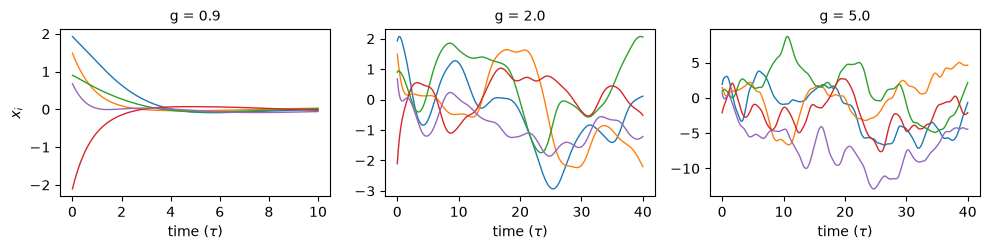

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, g, T in zip(axes, (0.9, 2.0, 5.0), (10.0, 40.0, 40.0)):
    net = RandomRNN(N=N, g=g, seed_net=0)
    net.W = net.W.double()
    torch.manual_seed(42)
    x0 = torch.randn(N).double()
    X = simulate_rk4(net, x0, T)
    ax.plot(np.arange(len(X)) * dt, X[:, :5], lw=1)
    ax.set_title(f"g = {g}", fontsize=10)
    ax.set_xlabel("time ($\\tau$)")
axes[0].set_ylabel("$x_i$")
fig.tight_layout()

### Three architectures (Figure 1B)

- **Random**: Gaussian weights with variance $g^2/N$, no self-connections (Sompolinsky et al., 1988).
- **Dynamically critical**: the same random matrix, with 30% of its eigenvalues moved to just below the
  instability boundary (real part 0.99), then scaled by $g$.
- **Barcode**: the network of Fang et al. (2025): weights with mean $\mu/N$ ($\mu = -40$, global inhibition)
  and variance $g^2/N$, self-connections kept. $g = 7$ is their operating point.

Each network has N = 1000. After a 200 τ transient, plot 40 τ of five units. Barcode activity is sparse,
so, as in Figure 1, its five most active units are shown.

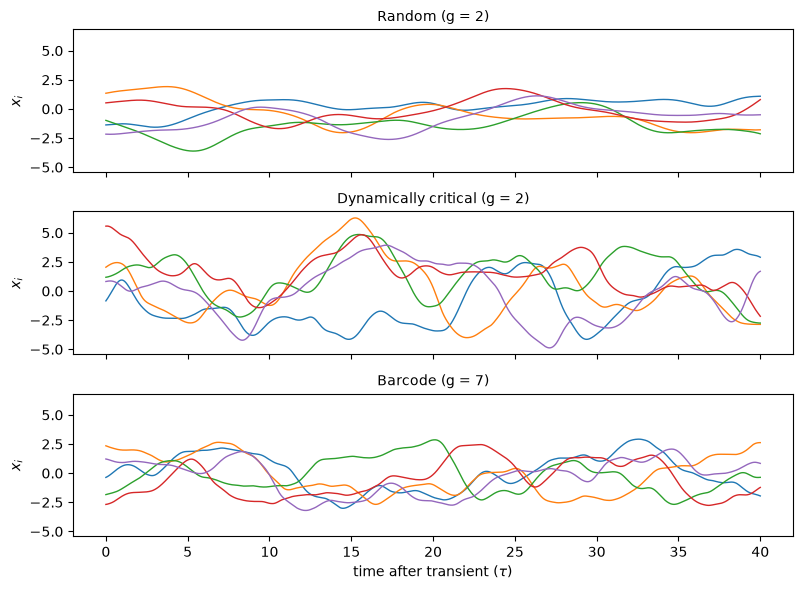

In [4]:
models = {
    "Random (g = 2)": RandomRNN(N=N, g=2.0, seed_net=0),
    "Dynamically critical (g = 2)": DynamicallyCriticalRNN(N=N, g=2.0, seed_net=0, shift=0.01,
                                                           critical_modes_fraction=0.30),
    "Barcode (g = 7)": BarcodeRNN(N=N, g=7.0, seed_net=0, keep_diag=True),
}

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True, sharey=True)
for ax, (name, net) in zip(axes, models.items()):
    torch.manual_seed(42)
    X = simulate_rk4(net, torch.randn(N), T=40.0, T_skip=200.0)
    if name.startswith("Barcode"):
        units = np.argsort(np.maximum(X, 0).mean(axis=0))[::-1][:5]   # most active units
    else:
        units = np.arange(5)
    ax.plot(np.arange(len(X)) * dt, X[:, units], lw=1)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("$x_i$")
axes[-1].set_xlabel("time after transient ($\\tau$)")
fig.tight_layout()

## 2. Lyapunov spectrum of the random network

`LyapunovSpectrum.compute()` evolves the state together with $N$ tangent vectors, using the exact tangent
map of the RK4 step, and re-orthonormalizes them with a QR decomposition every `T_ONS`. The time average
of $\log |R_{ii}|$ gives the exponents $\lambda_1 \ge \dots \ge \lambda_N$. From the spectrum:

- $\lambda_1$, the largest exponent: positive means chaos;
- $H = \sum_{\lambda_i > 0} \lambda_i$, the entropy rate (nats per $\tau$);
- $D$, the Kaplan-Yorke attractor dimension.

To keep this fast, the network is small (N = 100) and the runs are much shorter than in the paper's
simulations, so the numbers are illustrative.

In [5]:
settings = dict(dt=0.05, T_transient=50.0, T_ONS_warmup=20.0, T_sim=300.0, integrator="rk4")

results = {}
for g in (0.5, 3.0):
    t0 = time.perf_counter()
    res = LyapunovSpectrum(RandomRNN(N=100, g=g, seed_net=0)).compute(**settings)
    results[g] = res
    print(f"g = {g}: lambda_1 = {res.max_exponent:+.3f}, H = {res.entropy:.3f}, "
          f"D = {res.lyapunov_dimension:.2f}   ({time.perf_counter() - t0:.1f} s)")

g = 0.5: lambda_1 = -0.578, H = 0.000, D = 0.00   (5.4 s)


g = 3.0: lambda_1 = +0.091, H = 0.141, D = 5.25   (5.2 s)


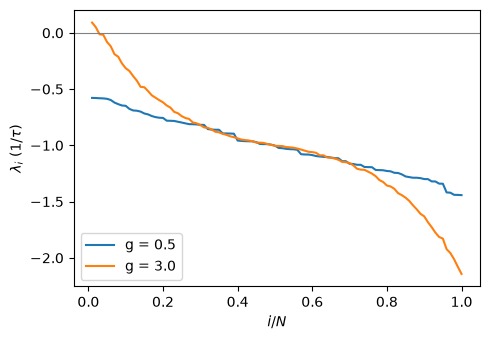

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for g, res in results.items():
    ax.plot(np.arange(1, 101) / 100, res.spectrum, label=f"g = {g}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("$i / N$")
ax.set_ylabel("$\\lambda_i$ ($1/\\tau$)")
ax.legend()
fig.tight_layout()

At $g = 0.5$ every exponent is negative: activity decays to the fixed point at zero. At $g = 3$ the
leading exponents are positive, the hallmark of chaos, and $H$ and $D$ measure how much.

Spectra for the Dynamically critical and Barcode networks are part of a manuscript in preparation and
are not shown here.